# Assignment: Video Quality Inference

To this point in the class, you have learned various techniques for leading and analyzing packet captures of various types, generating features from those packet captures, and training and evaluating models using those features.

In this assignment, you will put all of this together, using a network traffic trace to train a model to automatically infer video quality of experience from a labeled traffic trace.

## Getting the data

Everything you need is in the course data repository on GitHub, [noise-courses/data](https://github.com/noise-courses/data), under `video-qoe/`. Either clone the whole repository (about 110 MB):

```
git clone https://github.com/noise-courses/data.git
```

or fetch just the files you need with the `wget` lines given in each part below. The four files are:

| File | Used in | Size |
|---|---|---|
| `netflix.pcap` | Part 1 | 22 MB |
| `netflix_dataset.pkl.xz` *or* `video_dataset.pkl.xz` | Part 2 | 22 MB / 61 MB compressed |
| `netflix_session.pkl` | Part 3 | 130 KB |

## Part 1: Warmup

The first part of this assignment builds directly on the hands-on activities but extends them slightly.

### Extract Features from the Network Traffic

Load the `netflix.pcap` file, which is a packet trace that includes network traffic:

```
!wget https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/netflix.pcap
```



# Video Quality Inference

For this assignment, I use network traffic to predict the resolution of a Netflix video. First, I find Netflix traffic in a packet capture and calculate some features. Then I train and test a random forest using the labeled dataset. Finally, I use the model to predict the resolution during a separate Netflix session.

I chose the smaller Netflix-only dataset. Predicting resolution tells me something about video quality, but it does not tell me everything about the viewing experience, such as whether the video is buffering.

In [2]:
%pip -q install pandas numpy scikit-learn scapy matplotlib

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
DATA = Path('data')
DATA.mkdir(exist_ok=True)

base_url = 'https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/'
files = ['netflix.pcap', 'netflix_dataset.pkl.xz', 'netflix_session.pkl']

for filename in files:
    filepath = DATA / filename
    if not filepath.exists():
        urllib.request.urlretrieve(base_url + filename, filepath)
    print(filename, 'is ready')

netflix.pcap is ready
netflix_dataset.pkl.xz is ready
netflix_session.pkl is ready


### Identifying the Service Type

Use the DNS traffic to filter the packet trace for Netflix traffic.

## Part 1 — Find Netflix traffic using DNS

I start by looking at DNS responses for Netflix-related domain names. DNS connects a name to an IP address. Some responses point to another name first, so I followed those aliases too. I then keep packets that go to or come from the IP addresses I found.

This gives me a way to find Netflix-related traffic in this capture. It is not perfect: some addresses may be shared, and a DNS lookup might have happened before the capture started. Also, Netflix-related traffic can include things besides the video itself.

In [ ]:
from scapy.all import PcapReader, DNS, DNSRR, IP, IPv6, TCP, UDP

def name_text(value):
    if isinstance(value, bytes):
        value = value.decode(errors='replace')
    return str(value).lower().rstrip('.')

dns_records = []
with PcapReader(str(DATA / 'netflix.pcap')) as packets:
    for packet in packets:
        if DNS not in packet or not packet[DNS].qr:
            continue
        for section in [packet[DNS].an, packet[DNS].ns, packet[DNS].ar]:
            for rr in section:
                if isinstance(rr, DNSRR) and rr.type in [1, 5, 28]:
                    dns_records.append((float(packet.time), name_text(rr.rrname),
                                        int(rr.type), name_text(rr.rdata), int(rr.ttl)))
dns = pd.DataFrame(dns_records, columns=['time', 'name', 'type', 'value', 'ttl']).drop_duplicates()
suffixes = ('netflix.com', 'netflix.net', 'nflxvideo.net', 'nflximg.net', 'nflximg.com', 'nflxso.net', 'nflxext.com')
def netflix_name(name):
    for suffix in suffixes:
        if name == suffix or name.endswith('.' + suffix):
            return True
    return False
known_names = set()
for name in set(dns['name']) | set(dns['value']):
    if netflix_name(name):
        known_names.add(name)
while True:
    aliases = set(dns.loc[(dns['type'] == 5) & dns['name'].isin(known_names), 'value'])
    if aliases <= known_names:
        break
    known_names.update(aliases)
netflix_dns = dns[dns['name'].isin(known_names)]
netflix_ips = set(netflix_dns.loc[netflix_dns['type'].isin([1, 28]), 'value'])
assert netflix_ips, 'No Netflix DNS addresses found.'
display(netflix_dns[['name', 'type', 'value', 'ttl']].drop_duplicates())
print('Netflix-associated IPs:', sorted(netflix_ips))

Netflix-associated IPs: ['198.38.120.130', '198.38.120.134', '198.38.120.137', '198.38.120.153', '198.38.120.162', '198.38.120.164', '198.38.120.166', '198.38.120.167', '34.252.77.54', '52.19.39.146', '52.208.128.101', '52.210.133.255', '52.210.19.176', '52.48.148.78', '52.48.8.150']


,name,type,value,ttl
12,ipv4-c001-cdg001-ix.1.oca.nflxvideo.net,1,198.38.120.130,560
13,www.eu-west-1.prodaa.netflix.com,1,52.19.39.146,60
14,customerevents.eu-west-1.prodaa.netflix.com,1,52.210.19.176,60
15,ipv4-c024-cdg001-ix.1.oca.nflxvideo.net,1,198.38.120.153,3600
18,occ-0-56-55.1.nflxso.net,1,198.38.120.137,30
21,ipv4-c072-cdg001-ix.1.oca.nflxvideo.net,1,198.38.120.167,3600
42,push.prod.eu-west-1.prodaa.netflix.com,1,34.252.77.54,60
43,ipv4-c005-cdg001-ix.1.oca.nflxvideo.net,1,198.38.120.134,3600
44,ipv4-c069-cdg001-ix.1.oca.nflxvideo.net,1,198.38.120.164,3600
45,ipv4-c071-cdg001-ix.1.oca.nflxvideo.net,1,198.38.120.166,3600


### Generate Statistics

Generate statistics and features for the Netflix traffic flows. Use the `netml` library or any other technique that you choose to generate a set of features that you think would be good features for your model. 

In [ ]:
rows = []
capture_start = None
seen_tcp = set()
with PcapReader(str(DATA / 'netflix.pcap')) as packets:
    for packet in packets:
        t = float(packet.time)
        if capture_start is None:
            capture_start = t
        network = packet.getlayer(IP) or packet.getlayer(IPv6)
        if network is None:
            continue
        src, dst = network.src, network.dst
        if src not in netflix_ips and dst not in netflix_ips:
            continue
        transport = packet.getlayer(TCP) or packet.getlayer(UDP)
        if transport is None:
            continue
        protocol = 'TCP' if TCP in packet else 'UDP'
        down = src in netflix_ips
        if down:
            server = (src, int(transport.sport))
            client = (dst, int(transport.dport))
        else:
            server = (dst, int(transport.dport))
            client = (src, int(transport.sport))
        flow = (protocol, client, server)
        payload = len(bytes(transport.payload))
        duplicate = False
        if protocol == 'TCP' and payload:
            key = (flow, down, int(transport.seq), payload)
            duplicate = key in seen_tcp
            seen_tcp.add(key)
        unique_payload = payload
        if duplicate:
            unique_payload = 0
        rows.append((t - capture_start, flow, down, len(packet), payload, unique_payload))
traffic = pd.DataFrame(rows, columns=['time_s', 'flow', 'down', 'wire_bytes', 'payload_bytes', 'unique_payload_bytes'])
traffic = traffic.sort_values('time_s').reset_index(drop=True)
assert len(traffic), 'DNS filtering produced no transport packets.'
print(f'{len(traffic):,} matching packets in {traffic.flow.nunique()} bidirectional flows')
display(traffic.head())

138,633 matching packets in 55 bidirectional flows


,time_s,flow,down,wire_bytes,payload_bytes,unique_payload_bytes
0,2.368591,"(TCP, (192.168.43.72, 58451), (198.38.120.130,...",False,78,0,0
1,2.368637,"(TCP, (192.168.43.72, 58452), (198.38.120.130,...",False,78,0,0
2,2.368733,"(TCP, (192.168.43.72, 58453), (198.38.120.130,...",False,78,0,0
3,2.368943,"(TCP, (192.168.43.72, 58454), (52.19.39.146, 4...",False,78,0,0
4,2.369006,"(TCP, (192.168.43.72, 58455), (52.19.39.146, 4...",False,78,0,0


**Write a brief justification for the features that you have chosen.**


Because the traffic is encrypted, I cannot directly see where each video segment starts and ends. Instead, I estimate segment downloads by looking for bursts of data coming from the server. In my approach, a gap longer than 0.25 seconds starts a new burst. I only count bursts with at least 20 KB of data, which helps leave out small exchanges.

I count each burst in the window where it ends. For a full ten-second window, the segment-download rate is the number of counted bursts divided by 10. For example, three bursts in ten seconds gives a rate of 0.3 estimated segments per second. I skip exact repeats of TCP sequence numbers and payload lengths when counting burst bytes, although this does not catch every kind of retransmission.

This is an estimate, since one burst could contain several segments or other data, such as audio. The table below shows how the number of estimated segments changes when I change the gap and size thresholds.

I chose these features because they describe how much data is being downloaded and how it arrives:

- **Download and upload rates:** show how much traffic moves in each direction.
- **Downloaded payload bytes:** show how much actual transport payload arrives, after removing the exact repeats described above.
- **Average packet size and its variation:** help describe whether packets are mostly large downloads or smaller exchanges.
- **Time between packets and its variation:** describe whether the data arrives steadily or in bursts.
- **Upload/download byte ratio:** helps describe the balance between requests and downloads.
- **Number of active flows:** shows how many connections are being used.
- **Estimated segment count, rate, and size:** describe how often larger downloads happen and how big they are.

I calculate these features in ten-second windows to match the assignment. I keep empty windows too. If the last window is shorter than ten seconds, I divide by its actual observed length when calculating rates.

### Inferring Segment downloads

In addition to the features that you could generate using the `netml` library or similar, add to your feature vector a "segment downloads rate" feature, which indicates the number of video segments downloaded for a given time window.

Note: If you are using the `netml` library, generating features with `SAMP` style options may be useful, as this option gives you time windows, and you can then simply add the segment download rate to that existing dataframe.

,window,start_s,duration_s,down_bytes,up_bytes,down_payload_bytes,down_mbps,up_mbps,packets,active_flows,mean_down_payload,std_down_payload,mean_down_iat_s,std_down_iat_s,up_down_byte_ratio,estimated_segments,segment_download_rate,mean_segment_bytes
0,0,0.0,10.0,35879,25506,17131,0.028703,0.020405,513,29,83.239496,61.603617,0.029097,0.061699,0.710889,0,0.0,0.0
1,1,10.0,10.0,38898,20199,23840,0.031118,0.016159,440,30,106.079646,54.067173,0.042292,0.104942,0.519281,0,0.0,0.0
2,2,20.0,10.0,58726,23545,36236,0.046981,0.018836,604,21,111.836364,48.678574,0.029724,0.035403,0.400930,0,0.0,0.0
3,3,30.0,10.0,52190,18059,34170,0.041752,0.014447,493,4,126.583026,30.640872,0.036967,0.065908,0.346024,0,0.0,0.0
4,4,40.0,10.0,47066,11292,31356,0.037653,0.009034,401,4,133.432203,8.704157,0.042468,0.070682,0.239918,0,0.0,0.0
5,5,50.0,10.0,64403,14628,43019,0.051522,0.011702,546,4,132.774691,12.676720,0.030870,0.060846,0.227132,0,0.0,0.0
6,6,60.0,10.0,2160963,487228,1443949,1.728770,0.389782,17774,15,132.923594,11.611158,0.000920,0.002353,0.225468,5,0.5,68913.0
7,7,70.0,10.0,2376351,436968,1591215,1.901081,0.349574,18331,8,133.760508,5.448594,0.000840,0.000588,0.183882,0,0.0,0.0
8,8,80.0,10.0,770029,155494,515199,0.616023,0.124395,6151,4,133.644542,6.663310,0.002589,0.012427,0.201933,3,0.3,1039520.0
9,9,90.0,10.0,35956,10012,24010,0.028765,0.008010,320,3,132.651934,12.753306,0.043622,0.090417,0.278451,0,0.0,0.0


,gap_s,minimum_bytes,estimated_segments
0,0.10,10000,81
1,0.10,20000,61
2,0.10,50000,54
3,0.25,10000,82
4,0.25,20000,61
5,0.25,50000,55
6,0.50,10000,81
7,0.50,20000,61
8,0.50,50000,55


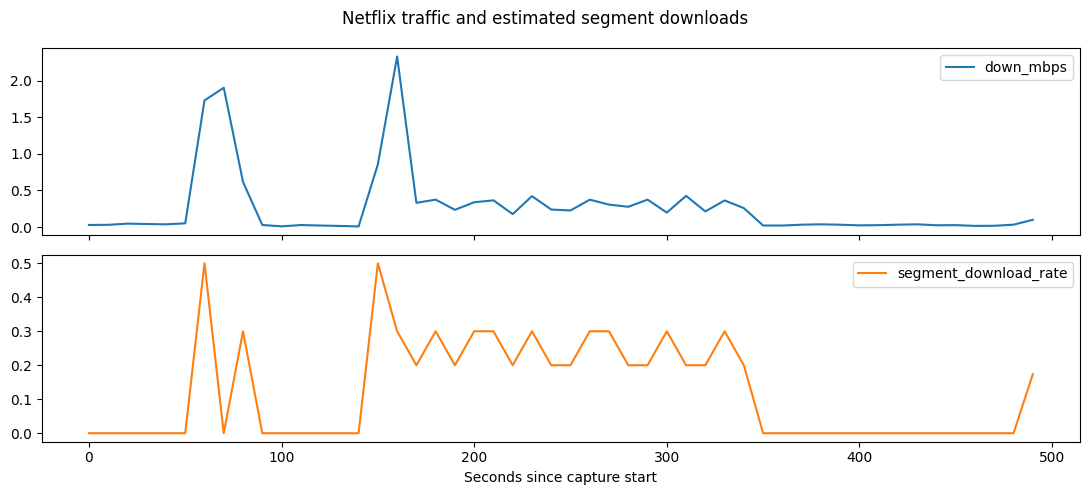

In [ ]:
WINDOW = 10.0
end_s = float(traffic.time_s.max())
n_windows = int(np.floor(end_s / WINDOW)) + 1
traffic['window'] = (traffic.time_s // WINDOW).astype(int)

def infer_bursts(gap=0.25, min_bytes=20_000):
    records = []
    eligible = traffic[traffic.down & (traffic.unique_payload_bytes > 0)]
    for flow, group in eligible.groupby('flow', sort=False):
        group = group.sort_values('time_s').copy()
        group['burst'] = group.time_s.diff().gt(gap).cumsum()
        for _, burst in group.groupby('burst'):
            size = int(burst.unique_payload_bytes.sum())
            if size >= min_bytes:
                records.append((burst.time_s.iloc[0], burst.time_s.iloc[-1], size))
    result = pd.DataFrame(records, columns=['start_s', 'end_s', 'bytes'])
    result['window'] = (result.end_s // WINDOW).astype(int)
    return result

bursts = infer_bursts()
features = []
for w in range(n_windows):
    group = traffic[traffic.window == w]
    down = group[group.down]
    up = group[~group.down]
    duration = min(WINDOW, max(end_s - w * WINDOW, 1e-9))
    sizes = down.payload_bytes
    iat = down.time_s.diff().dropna()
    b = bursts[bursts.window == w]
    row = {}
    row['window'] = w
    row['start_s'] = w * WINDOW
    row['duration_s'] = duration
    row['down_bytes'] = int(down.wire_bytes.sum())
    row['up_bytes'] = int(up.wire_bytes.sum())
    row['down_payload_bytes'] = int(down.unique_payload_bytes.sum())
    row['down_mbps'] = row['down_bytes'] * 8 / duration / 1_000_000
    row['up_mbps'] = row['up_bytes'] * 8 / duration / 1_000_000
    row['packets'] = len(group)
    row['active_flows'] = group.flow.nunique()
    row['mean_down_payload'] = sizes.mean()
    row['std_down_payload'] = sizes.std(ddof=0)
    row['mean_down_iat_s'] = iat.mean()
    row['std_down_iat_s'] = iat.std(ddof=0)
    row['up_down_byte_ratio'] = row['up_bytes'] / max(row['down_bytes'], 1)
    row['estimated_segments'] = len(b)
    row['segment_download_rate'] = len(b) / duration
    row['mean_segment_bytes'] = b.bytes.mean()
    features.append(row)

traffic_features = pd.DataFrame(features).fillna(0)
display(traffic_features.head(12))
sensitivity = []
for gap in [0.1, 0.25, 0.5]:
    for size in [10_000, 20_000, 50_000]:
        count = len(infer_bursts(gap, size))
        sensitivity.append({'gap_s': gap, 'minimum_bytes': size,
                            'estimated_segments': count})
display(pd.DataFrame(sensitivity))
traffic_features.plot(x='start_s', y=['down_mbps', 'segment_download_rate'], subplots=True,
                      figsize=(11, 5), title='Netflix traffic and estimated segment downloads')
plt.xlabel('Seconds since capture start')
plt.tight_layout()
plt.show()

## Part 2: Video Quality Inference

You will now load the complete video dataset from a previous study to train and test models based on these features to automatically infer the quality of a streaming video flow.

For this part of the assignment, you will need two pickle files. They are hosted in the course data repository on GitHub, [noise-courses/data](https://github.com/noise-courses/data), in the `video-qoe/` directory. Download them by running the code below:

```
!wget https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/netflix_session.pkl
!wget https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/video_dataset.pkl.xz
!xz -d video_dataset.pkl.xz
```

The dataset is stored xz-compressed in the repository (61 MB compressed, about 265 MB uncompressed), so the last line decompresses it. If `xz` is not available on your system, you can decompress it in Python instead:

```python
import lzma, shutil
with lzma.open('video_dataset.pkl.xz') as f_in, open('video_dataset.pkl', 'wb') as f_out:
    shutil.copyfileobj(f_in, f_out)
```

A smaller Netflix-only dataset (`netflix_dataset.pkl.xz`, 52,279 samples with 251 features) is available in the same directory and may be used instead of the multi-service `video_dataset.pkl` (204,713 samples with 170 features).

**Backup (Google Drive):** If GitHub is unavailable, the Netflix-only dataset is also mirrored on Google Drive. This link only works through `gdown` (`pip install gdown`); opening it with `wget`, `curl`, or a browser returns a virus-scan HTML page instead of the file:

```
!gdown 'https://drive.google.com/uc?id=1iI1tos08p9FJBI-ADR9b_iFObWRwXANX' -O netflix_dataset.pkl
```

### Load the File

Load the video dataset pickle file.

In [26]:
dataset = pd.read_pickle(DATA / 'netflix_dataset.pkl.xz')
session = pd.read_pickle(DATA / 'netflix_session.pkl')
VALID = [240, 360, 480, 720, 1080]
print('Raw training shape:', dataset.shape, '| session:', session.shape)
print('Original resolution counts:')
display(dataset.resolution.value_counts(dropna=False).sort_index())

Raw training shape: (52279, 251) | session: (59, 251)
Original resolution counts:


resolution
0.0        2531
240.0      1701
360.0      4476
480.0     29486
720.0      9457
1080.0     4628
Name: count, dtype: int64

### Clean the File

1. The dataset contains video resolutions that are not valid. Remove entries in the dataset that do not contain a valid video resolution. Valid resolutions are 240, 360, 480, 720, 1080.

I remove invalid resolutions. I also leave out the whole Part 3 session before training, so it stays a separate check of the model.

In [27]:
clean = dataset[dataset.resolution.isin(VALID)].copy()
print('Removed invalid-resolution rows:', len(dataset) - len(clean))
reserved_ids = set(session.session_id.dropna())
reserved_deployments = set(session.deployment_session_id.dropna())
reserved = clean.session_id.isin(reserved_ids) | clean.deployment_session_id.isin(reserved_deployments)
print('Removed rows belonging to the Part 3 session:', int(reserved.sum()))
clean = clean.loc[~reserved].reset_index(drop=True)
assert not clean.session_id.isin(reserved_ids).any()

Removed invalid-resolution rows: 2531
Removed rows belonging to the Part 3 session: 59


2. The file also contains columns that are unnecessary (in fact, unhelpful!) for performing predictions. Identify those columns, and remove them.

In [28]:
extra = [
    'is_tcp', 'parallel_flows', 'n_chunks_down', 'n_chunks_up',
    'up_down_ratio', 'total_throughput_down', 'total_throughput_up',
    'service_Video_throughput_down', 'service_Video_throughput_up',
    'service_non_video_throughput_down', 'service_non_video_throughput_up'
]

feature_cols = []
for column in clean.columns:
    if column.startswith(('server', 'user')) or column in extra:
        feature_cols.append(column)

removed_columns = []
for column in clean.columns:
    if column not in feature_cols:
        removed_columns.append(column)

display(pd.DataFrame({'unused_column': removed_columns}))

,unused_column
0,10_EWMA_chunksizes
1,10_avg_chunksize
2,10_chunksizes_50
3,10_chunksizes_50R
4,10_chunksizes_75
...,...
119,startup3.3
120,startup6.6
121,startup5
122,startup10


**Briefly explain why you removed those columns.**
I removed columns like session IDs, video IDs, and timestamps because they identify a recording rather than describe its traffic. I also removed player information, such as bitrate and quality, because it could give away the resolution and would not be available from network traffic alone. I kept the traffic features so the model could learn patterns in how the video data was downloaded.

## Part 2 — Load and clean the labeled dataset

The packet capture from Part 1 does not give me a resolution label for each window. For training, I therefore use the Netflix dataset provided with the assignment. It already contains traffic features and resolution labels. The Part 1 features are a separate exercise; I do not combine those rows with the labeled dataset.

First, I remove rows whose resolution is not 240, 360, 480, 720, or 1080. I also found that the session used in Part 3 appears in the training dataset. I remove that whole session before training so the model cannot learn from the same session it will later predict.

Next, I choose the model inputs. I keep the `server*` and `user*` network statistics, throughput measurements, number of flows, protocol indicator, and chunk counts. I also add `n_chunks_down / 10` as a segment-download rate for the ten-second windows. These chunk counts come from the study, so they may use a different definition than my burst estimate in Part 1.

I leave out the following types of columns:

- **Resolution:** this is the answer I want to predict, so it cannot also be an input.
- **Session IDs, home IDs, video IDs, service, row indices, and timestamps:** these could help the model recognize a recording instead of learning useful traffic patterns.
- **Player information, such as quality, bitrate, startup time, buffering, and resolution switches:** some of these are closely related to the answer, and I would not necessarily know them from traffic alone.
- **Historical chunk summaries and nested EWMA values:** I could not verify how these were calculated or whether they only use information available at that moment. Some summaries also stay the same throughout the supplied session.
- **Other environment and chunk measurements:** I leave these out to keep a smaller, clearly defined set of traffic inputs.

The table above lists the unused columns, and the list here explains the main reasons for leaving them out. Some excluded columns might be useful, but I chose to be careful about including information that could make the results misleading.

### Prepare Your Data

Prepare your data matrix, determine your features and labels, and perform a train-test split on your data.

In [ ]:
def make_X(frame):
    result = frame[feature_cols].astype(float)
    result = result.replace([np.inf, -np.inf], np.nan)
    result['segment_download_rate'] = pd.to_numeric(frame.n_chunks_down, errors='coerce') / 10.0
    return result
X = make_X(clean)
y = clean.resolution.astype(int)
groups = clean.session_id
print('Candidate features:', X.shape[1], '| valid samples:', len(X), '| sessions:', groups.nunique())

Candidate features: 128 | valid samples: 49689 | sessions: 997


### Split the data into training and test sets

I split by session instead of randomly splitting individual rows. Rows from the same video session are related, so putting them in both sets could make the model look better than it really is.

I use `StratifiedGroupKFold` to keep each session together while trying to keep the resolution classes reasonably balanced. One of five folds becomes the test set, which is about 20% of the data. I use three more folds within the training set to tune the model. The separate Part 3 session is not included in either set.

The pipeline fills missing values with training-data medians and removes features that do not vary in the training data. These steps are learned separately inside each training fold, so they do not use the test data.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, roc_curve, auc, roc_auc_score)
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]
assert set(g_train).isdisjoint(set(g_test))
assert set(y_train) == set(VALID) == set(y_test)
display(pd.DataFrame({'train': y_train.value_counts(), 'test': y_test.value_counts()}).sort_index())
print('Train/test sessions:', g_train.nunique(), g_test.nunique())

Train/test sessions: 799 198


,train,test
resolution,,
240,1330,364
360,3469,1001
480,23482,5993
720,7672,1758
1080,4006,614


### Train and Tune Your Model

1. Select a model of your choice.
2. Train the model using your training data.

### Train and tune the model

I chose a random forest, which combines predictions from many decision trees. It can learn relationships between several traffic features without requiring me to put all the features on the same scale. It also gives class probabilities, which I need for the ROC curves.

I try eight combinations of settings, including tree depth, minimum samples per leaf, the number of features considered at each split, and class weighting. Class weighting can help when some resolutions have many more examples than others.

I choose the best settings using macro F1. This gives each resolution class equal weight, so the most common resolution does not dominate the score. Each combination is checked with three training/validation splits that keep sessions separate. After that, the best combination is trained on the whole training set. This finds the best option among the settings I tried, but it does not mean there are no better settings.

In [ ]:
pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
    ('variance', VarianceThreshold()),
    ('model', RandomForestClassifier(n_estimators=180, random_state=SEED, n_jobs=2))
])
params = {'model__max_depth': [12, 24, None],
          'model__min_samples_leaf': [1, 3, 8],
          'model__max_features': ['sqrt', 0.5],
          'model__class_weight': [None, 'balanced_subsample']}
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED+1)
search = RandomizedSearchCV(pipeline, params, n_iter=8, scoring='f1_macro',
    cv=cv, random_state=SEED, n_jobs=1, refit=True, return_train_score=False)

### Tune Your Model

Perform hyperparameter tuning to find optimal parameters for your model.

In [ ]:
search.fit(X_train, y_train, groups=g_train)
model = search.best_estimator_
print('Best parameters:', search.best_params_)
print('Best cross-validation macro F1:', round(search.best_score_, 4))
display(pd.DataFrame(search.cv_results_)[['rank_test_score', 'mean_test_score', 'std_test_score', 'params']].sort_values('rank_test_score'))

### Evaluate Your Model

Evaluate your model accuracy according to the following metrics:

1. Accuracy
2. F1 Score
3. Confusion Matrix
4. ROC/AUC

### Evaluate the model on the test set

Now I test the selected model on data that was not used to train or tune it. I also compare it with a simple baseline that always predicts the most common resolution.

- **Accuracy:** the fraction of windows predicted correctly.
- **Macro F1:** combines precision and recall, then gives each resolution equal weight.
- **Weighted F1:** also combines precision and recall, but gives more weight to classes with more examples.
- **Confusion matrix:** shows which resolutions are getting mixed up. Rows are the true resolutions, and columns are the predictions.
- **ROC/AUC:** uses the model's probabilities to measure how well it separates each resolution from all the others. This approach is called one-vs-rest. A larger AUC means better separation, but it does not mean every final prediction is correct.

I report both macro AUC, which weights each class equally, and weighted AUC, which accounts for how common each class is.

,model,accuracy,macro_F1,weighted_F1
0,Majority baseline,0.6159,0.1525,0.4695
1,Tuned random forest,0.7739,0.7111,0.7769


              precision    recall  f1-score   support

         240     0.4267    0.5440    0.4783       364
         360     0.6074    0.7682    0.6784      1001
         480     0.8644    0.8178    0.8404      5993
         720     0.6375    0.6092    0.6230      1758
        1080     0.9092    0.9625    0.9351       614

    accuracy                         0.7739      9730
   macro avg     0.6891    0.7403    0.7111      9730
weighted avg     0.7834    0.7739    0.7769      9730

One-vs-rest ROC AUC: macro=0.9255; weighted=0.8999


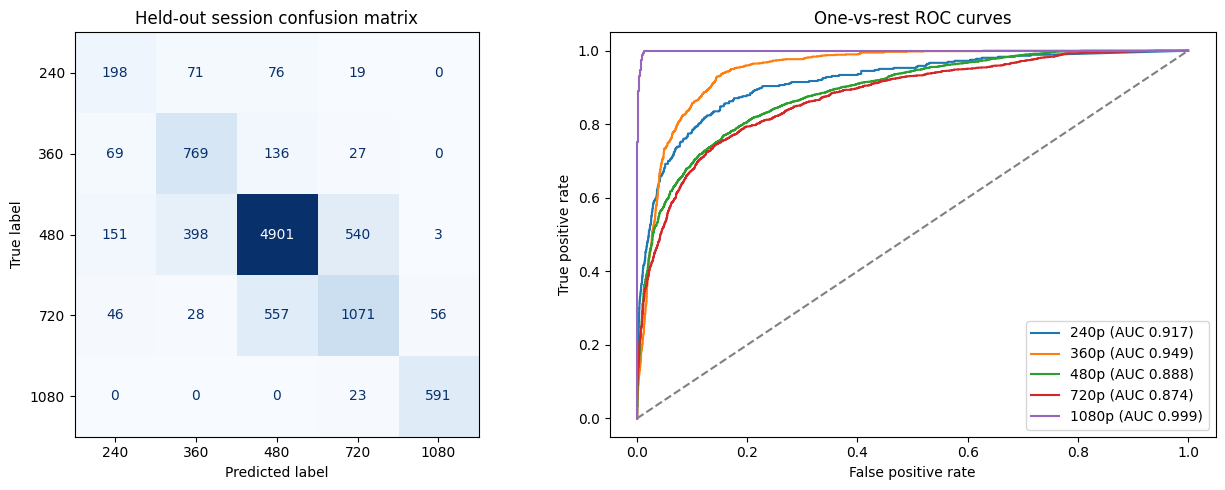

In [ ]:
prediction = model.predict(X_test)
probability = model.predict_proba(X_test)
classes = model.named_steps['model'].classes_
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
baseline_prediction = baseline.predict(X_test)
metrics = pd.DataFrame([
    {'model': 'Majority baseline', 'accuracy': accuracy_score(y_test, baseline_prediction),
     'macro_F1': f1_score(y_test, baseline_prediction, average='macro', zero_division=0),
     'weighted_F1': f1_score(y_test, baseline_prediction, average='weighted', zero_division=0)},
    {'model': 'Tuned random forest', 'accuracy': accuracy_score(y_test, prediction),
     'macro_F1': f1_score(y_test, prediction, average='macro'),
     'weighted_F1': f1_score(y_test, prediction, average='weighted')}])
display(metrics.round(4))
print(classification_report(y_test, prediction, labels=VALID, digits=4, zero_division=0))
macro_auc = roc_auc_score(y_test, probability, labels=classes, multi_class='ovr', average='macro')
weighted_auc = roc_auc_score(y_test, probability, labels=classes, multi_class='ovr', average='weighted')
print(f'One-vs-rest ROC AUC: macro={macro_auc:.4f}; weighted={weighted_auc:.4f}')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, prediction, labels=VALID, ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Held-out session confusion matrix')
class_aucs = []
for j, resolution in enumerate(classes):
    fpr, tpr, _ = roc_curve((y_test == resolution).astype(int), probability[:, j])
    value = auc(fpr, tpr)
    class_aucs.append((int(resolution), value))
    axes[1].plot(fpr, tpr, label=f'{resolution}p (AUC {value:.3f})')
axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[1].set(xlabel='False positive rate', ylabel='True positive rate', title='One-vs-rest ROC curves')
axes[1].legend()
plt.tight_layout()
plt.show()

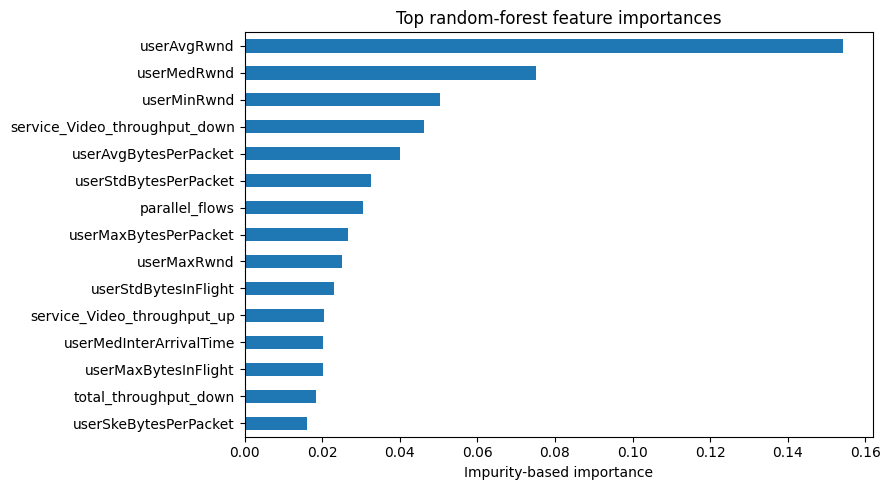

Held-out accuracy is 77.4%, macro F1 is 0.711, and macro AUC is 0.925.
Impurity importances are descriptive, can favor continuous variables, and do not establish causation.


In [ ]:
kept = X_train.columns[model.named_steps['variance'].get_support()]
importance = pd.Series(model.named_steps['model'].feature_importances_, index=kept).nlargest(15)
importance.sort_values().plot.barh(figsize=(9, 5), title='Top random-forest feature importances')
plt.xlabel('Impurity-based importance')
plt.tight_layout()
plt.show()
best = metrics.iloc[1]
print(f"Held-out accuracy is {best.accuracy:.1%}, macro F1 is {best.macro_F1:.3f}, and macro AUC is {macro_auc:.3f}.")
print('Impurity importances are descriptive, can favor continuous variables, and do not establish causation.')

## Part 3: Predict the Ongoing Resolution of a Real Netflix Session

Now that you have your model, it's time to put it in practice!

Use a preprocessed Netflix video session to infer **and plot** the resolution at 10-second time intervals. The session is `netflix_session.pkl` (downloaded in Part 2 above; 59 ten-second windows with the same 251 features as `netflix_dataset.pkl`, plus the true `resolution` so you can check yourself):

```python
session = pd.read_pickle('netflix_session.pkl')
```

## Part 3 — Predict resolution during a Netflix session

Here I use the model from Part 2 to predict the resolution for each ten-second window in the separate Netflix session. I already removed this session from the training dataset, so the model has not trained on it.

I put the rows in time order and make sure the feature columns match the training data. The true resolution is only used afterward to check the predictions. In the plot, each step represents one ten-second window.

These predictions use traffic observed during each window. They are estimates of the resolution during that window, rather than predictions of what the resolution will be in the future. Before using this in a live system, I would also need to check that the study's feature calculations never use later packets.

,time_s,predicted_resolution,true_resolution
0,10.0,720,480.0
1,20.0,480,480.0
2,30.0,480,720.0
3,40.0,720,720.0
4,50.0,720,720.0
5,60.0,720,720.0
6,70.0,480,720.0
7,80.0,480,1080.0
8,90.0,480,240.0
9,100.0,1080,240.0


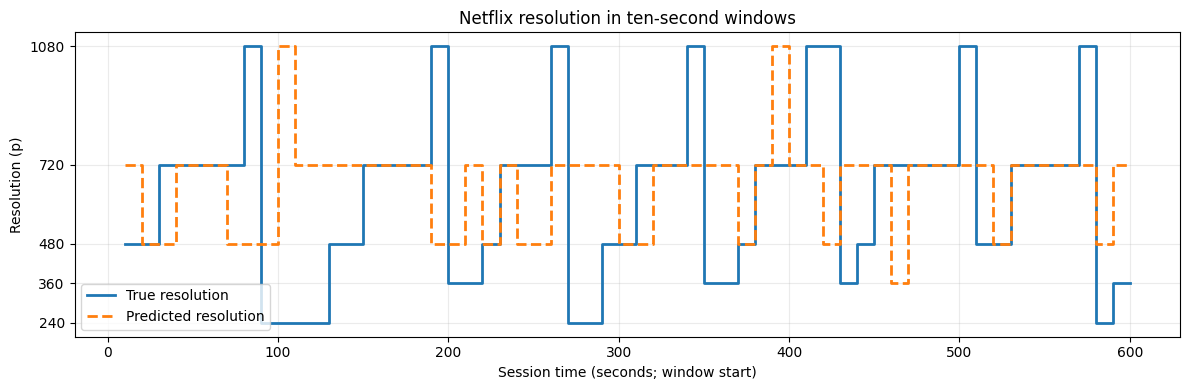

Session windows: 59
Session accuracy: 0.4237
Session macro F1 over classes present in truth or predictions: 0.1935


In [ ]:
session = session.sort_values('relative_timestamp').copy()
assert session.session_id.nunique() == 1
assert np.allclose(np.diff(session.relative_timestamp.to_numpy()), 10)
assert not set(session.session_id) & set(clean.session_id)
assert not set(session.deployment_session_id) & set(clean.deployment_session_id)
assert set(feature_cols) <= set(session.columns)
X_session = make_X(session).reindex(columns=X_train.columns)
session_predictions = model.predict(X_session)
results = pd.DataFrame({'time_s': session.relative_timestamp.to_numpy(),
                        'predicted_resolution': session_predictions,
                        'true_resolution': session.resolution.to_numpy()})
display(results)
fig, ax = plt.subplots(figsize=(12, 4))
times = np.r_[results.time_s, results.time_s.iloc[-1]+10]
for col, label, style in [('true_resolution', 'True resolution', '-'),
                          ('predicted_resolution', 'Predicted resolution', '--')]:
    values = np.r_[results[col], results[col].iloc[-1]]
    ax.step(times, values, where='post', linestyle=style, label=label, linewidth=2)
ax.set(xlabel='Session time (seconds; window start)', ylabel='Resolution (p)',
       title='Netflix resolution in ten-second windows', yticks=VALID)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
valid_session = results.true_resolution.isin(VALID)
print('Session windows:', len(results))
print('Session accuracy:', round(accuracy_score(results.loc[valid_session, 'true_resolution'],
                                               results.loc[valid_session, 'predicted_resolution']), 4))
print('Session macro F1 over classes present in truth or predictions:',
      round(f1_score(results.loc[valid_session, 'true_resolution'],
                     results.loc[valid_session, 'predicted_resolution'], average='macro', zero_division=0), 4))

## What I learned from the results

The model got 77.39% accuracy on the test set, with 0.711 macro F1, 0.777 weighted F1, and 0.925 macro AUC. This test set has 9,730 windows from 198 sessions. The baseline got 61.59% accuracy by always predicting 480p, so the random forest improved accuracy by about 15.8 percentage points.

The best macro F1 during tuning was 0.663. The test score is somewhat higher, which can happen because the validation and test sets contain different sessions.

The model did best on 1080p, which had an F1 score of 0.935, and had more trouble with 240p, which had an F1 score of 0.478. It also mixed up 480p and 720p quite often: 540 actual 480p windows were predicted as 720p, and 557 actual 720p windows were predicted as 480p. One possible reason is that different resolutions can produce similar traffic patterns, but this experiment does not prove why those mistakes happened.

The separate Netflix session was harder. The model got 25 out of 59 windows correct, or 42.37% accuracy, with a macro F1 of 0.194 across the classes present in the true labels or predictions. In the plot, the model often predicts 480p or 720p and misses short changes to other resolutions. This shows me that doing reasonably well across the test set does not mean the model will work equally well for every session. I did not change the model after seeing these results, because then this session would no longer be a separate check.

There are also limits to what I can conclude. The test checks new sessions from this dataset, but it does not tell me how well the model would work on different devices, homes, or streaming services. Windows from one session are also related, so they are not all independent examples.

For Part 1, the segment counts are estimates based on bursts. I do not have the real segment boundaries to check them against, and my definition may differ from the study's chunk counts. Finally, resolution is only one part of video quality. A high-resolution video can still buffer or have other playback problems.

## Acknowledgments

**Collaborators:** None

**Outside sources and code:**
- [Scapy documentation](https://scapy.readthedocs.io/en/latest/): packet and DNS parsing.
- [pandas read_pickle](https://pandas.pydata.org/docs/reference/api/pandas.read_pickle.html)
- [scikit-learn RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html), [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html), [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html), and [model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html): modeling and metrics.
- [Matplotlib](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.step.html): session plot.
AI tools used: - I used OpenAI Codex to help clean up the code and also clean up my writing.

